In [1]:
import os
import math

import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt

In [17]:
_dir = '/home/jan/Documents/EPFL/project_2/data/labels/dataset_small_v2'

dfs = []
for _file in os.listdir(_dir):
    
    if _file == 'labels.csv':
        continue
    print(_file)
    df = pd.read_csv(os.path.join(_dir, _file))
    dfs.append(df)


cocoa_1000.csv
coffee_maskell.csv
mapbiomas_1000.csv
regrowth_1000.csv
rubber_1000.csv
CAFI.csv
laos_shifting_agriculture_1000.csv


In [18]:
df = pd.concat(dfs)

In [19]:
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])


In [20]:
gdf = gpd.GeoDataFrame(df)
gdf['geometry'] = gdf.geometry.centroid

In [21]:
gdf = gdf.reset_index(drop=True)

In [23]:
np.unique(gdf.driver, return_counts=True)


(array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
        'mining', 'other', 'palm oil', 'pasture', 'rubber',
        'shifting agriculture', 'soy', 'urban'], dtype=object),
 array([1000,  336, 1022, 1000, 1002,   68, 1000, 1000, 1000, 1561, 1000,
        1021]))

In [26]:
#For now, not sure about the class 'other', would need more examples of that (can do with mapb)

gdf = gdf.loc[gdf.driver != 'other']

In [27]:
gdf

,geometry,driver,sampleid
0,POINT (-6.72678 5.50537),cocoa,3039418
1,POINT (-6.11368 5.47707),cocoa,3040124
2,POINT (-2.31246 5.53367),cocoa,3038914
3,POINT (-7.06634 6.10904),cocoa,3026449
4,POINT (-5.81185 6.35428),cocoa,3020208
...,...,...,...
11005,POINT (102.49297 20.76900),shifting agriculture,5000585
11006,POINT (101.56860 18.31633),shifting agriculture,5002529
11007,POINT (102.52126 20.80673),shifting agriculture,5000561
11008,POINT (102.93629 18.17485),shifting agriculture,5002562


In [28]:
pd.DataFrame(gdf).to_csv(_dir + '/labels.csv', index=False)

In [29]:
df = pd.DataFrame(gdf)

## Data split

In [62]:
def split_by_longitude(df, split =[ 'train', 'train', 'train','val']):
    # Splits dataset into train, val and test by degrees of latitude
    
    try:
        df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
    except TypeError: #if already a GeoSeries
        df['geometry'] = gpd.GeoSeries(df['geometry'])
    
    df['lon'] = df.geometry.apply(lambda geom: math.floor(geom.x)) 

    for i, lon in enumerate(range(-180, 180)):
        df.loc[df['lon'] == lon, 'split'] = split[i%len(split)]
    
    df = df.drop('lon', axis=1)
    return df
    #return df.loc[df.split == 'Tr'].copy(), df.loc[df.split == 'Val'].copy(), df.loc[df.split == 'T'].copy()

In [63]:
df = split_by_longitude(df)

In [145]:
#gpd.GeoDataFrame(df).to_file('../data/tmp/data_split.gpkg')

['cocoa' 'coffee' 'forest plantation' 'forest regrowth' 'mining'
 'palm oil' 'pasture' 'rubber' 'shifting agriculture' 'soy' 'urban'] [ 901  308  837  762  516  119  803  701 1249  674  663]
['cocoa' 'coffee' 'forest plantation' 'forest regrowth' 'mining'
 'palm oil' 'pasture' 'rubber' 'shifting agriculture' 'soy' 'urban'] [ 99  28 185 238 486 881 197 299 312 326 358]


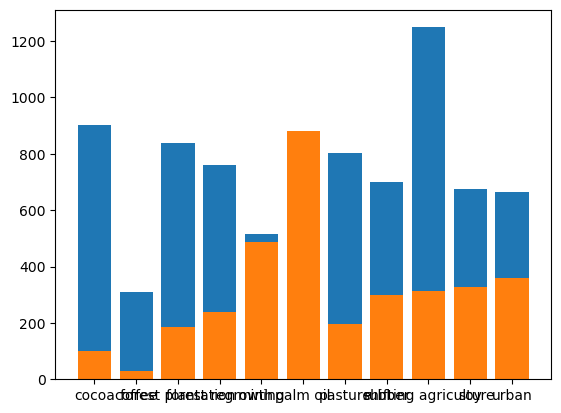

In [64]:
for dst in ['train', 'val']:
    
    classes, counts = np.unique(gdf.loc[gdf.split == dst].driver, return_counts=True)
    print(classes, counts)
    plt.bar(classes, height=counts)


In [66]:
df.to_csv(_dir + '/labels.csv', index=False)

In [59]:
df = pd.read_csv(_dir + '/labels.csv')

In [65]:
df

,geometry,driver,sampleid,split
0,POINT (-6.72678 5.50537),cocoa,3039418,train
1,POINT (-6.11368 5.47707),cocoa,3040124,train
2,POINT (-2.31246 5.53367),cocoa,3038914,train
3,POINT (-7.06634 6.10904),cocoa,3026449,train
4,POINT (-5.81185 6.35428),cocoa,3020208,train
...,...,...,...,...
10937,POINT (102.49297 20.76900),shifting agriculture,5000585,train
10938,POINT (101.56860 18.31633),shifting agriculture,5002529,train
10939,POINT (102.52126 20.80673),shifting agriculture,5000561,train
10940,POINT (102.93629 18.17485),shifting agriculture,5002562,train


In [54]:
#gdf = gpd.GeoDataFrame(df)
gpd.GeoDataFrame(df).to_file('../data/tmp/small_dst_v2.gpkg')